## Comparación Sentinel-1

1. Abrir el GeoTIFF de la polarización elegida usando el prefijo `zip://` de rasterio/GDAL
2. Envolver el dataset en un `WarpedVRT` a `EPSG:6668` para resolver la georreferenciación por GCPs.
3. Leer solo la ventana que cubre Chiba


In [1]:
import zipfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.vrt import WarpedVRT
from rasterio.windows import from_bounds

GRD_SCENES = {
    "2026-08-01": Path(r"C:\Users\Pedro\Documents\PSS\data\S1D_IW_GRDH_1SDV_20260801T204256_20260801T204321_003937_00721A_D375.SAFE.zip"),
    "2026-08-13": Path(r"C:\Users\Pedro\Documents\PSS\data\S1D_IW_GRDH_1SDV_20260813T204257_20260813T204322_004112_00782B_64E8.SAFE.zip"),
}

GRD_POLARIZATION = "vv"  # "vv" or "vh"
CHIBA_BBOX = (139.7, 34.85, 140.95, 36.05)  # lon_min, lat_min, lon_max, lat_max


def find_measurement_member(zip_path: Path, polarization: str) -> str:
    with zipfile.ZipFile(zip_path) as zf:
        return next(
            name for name in zf.namelist()
            if "/measurement/" in name and name.endswith(".tiff") and f"-{polarization}-" in name
        )


def read_window(zip_path: Path, polarization: str, bbox=CHIBA_BBOX, max_size=2000):
    """Open a Sentinel-1 GRD GeoTIFF, resolve its GCP-based georeferencing via a 
    WarpedVRT, and read only the window covering `bbox`, decimated to at most 
    `max_size` pixels per side."""
    member = find_measurement_member(zip_path, polarization)
    uri = f"zip://{zip_path}!{member}"
    with rasterio.open(uri) as src:
        with WarpedVRT(src, crs="EPSG:6668", resampling=Resampling.bilinear) as vrt:
            window = from_bounds(*bbox, transform=vrt.transform).round_offsets().round_lengths()
            out_h = max(1, min(max_size, int(window.height)))
            out_w = max(1, min(max_size, int(window.width)))
            data = vrt.read(1, window=window, out_shape=(out_h, out_w))
            transform = vrt.window_transform(window)
    return data, transform

In [2]:
grd_images = {}
grd_transforms = {}

for date, zip_path in GRD_SCENES.items():
    data, transform = read_window(zip_path, GRD_POLARIZATION)
    grd_images[date] = data
    grd_transforms[date] = transform
    print(f"{date}: {data.shape}, DN range [{data.min()}, {data.max()}]")

2026-08-01: (2000, 2000), DN range [0, 64807]
2026-08-13: (2000, 2000), DN range [0, 40891]


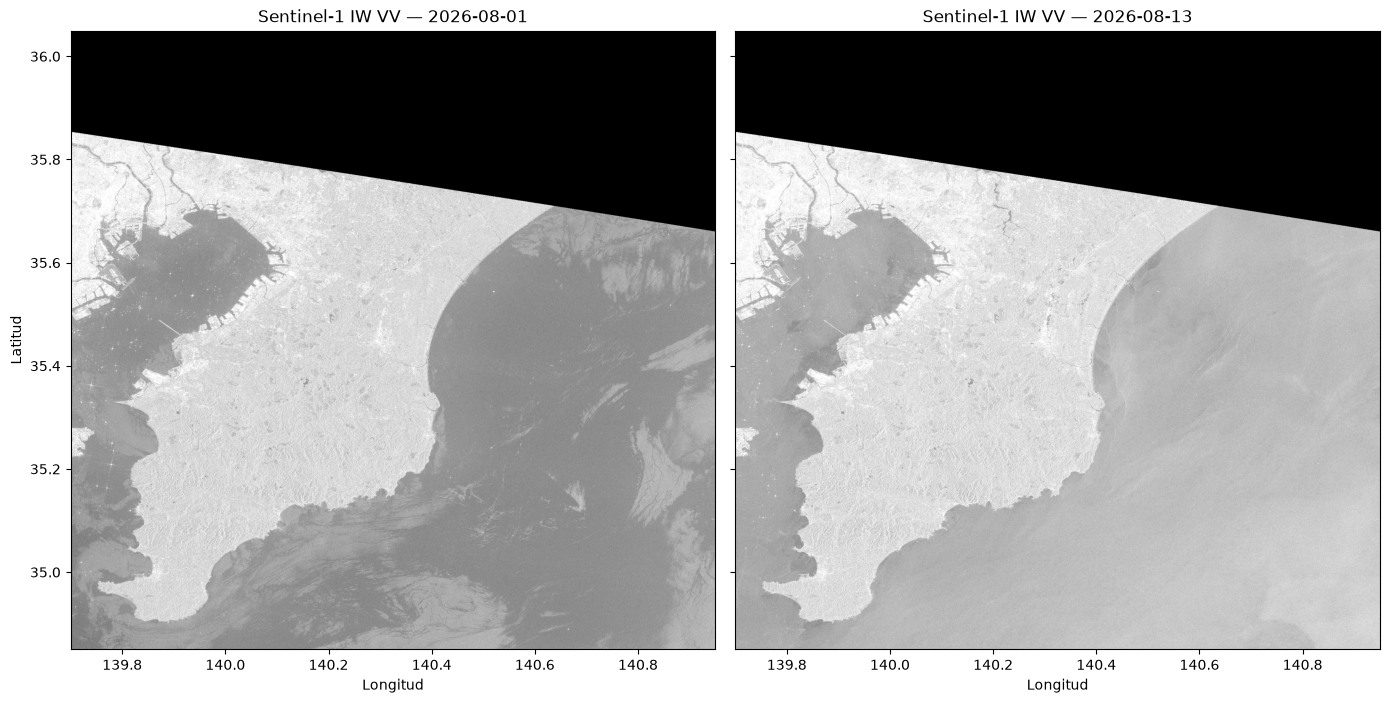

In [3]:
def to_db(dn):
    return 10 * np.log10(np.clip(dn.astype(float), 1, None) ** 2)

db_images = {date: to_db(dn) for date, dn in grd_images.items()}
vmin, vmax = np.percentile(np.concatenate([img.ravel() for img in db_images.values()]), [2, 98])
lon_min, lat_min, lon_max, lat_max = CHIBA_BBOX

fig, axes = plt.subplots(1, len(db_images), figsize=(14, 7), sharey=True)
for ax, (date, img) in zip(axes, db_images.items()):
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax, extent=(lon_min, lon_max, lat_min, lat_max))
    ax.set_title(f"Sentinel-1 IW {GRD_POLARIZATION.upper()} — {date}")
    ax.set_xlabel("Longitud")

axes[0].set_ylabel("Latitud")
plt.tight_layout()
plt.show()

## Máscara de inundación — Oamishirasato

1. Calibrar el DN crudo a **sigma-0 (dB)** real usando el LUT de calibración de cada escena (`annotation/calibration/calibration-*.xml`).
2. Georreferenciar cada sigma-0 (con sus GCP originales) y recortarlo a un grid común EPSG:6668 sobre Oamishirasato.
3. Filtrar speckle (mediana 5×5) y calcular la diferencia en dB — para VV y, por separado, para VH.
4. Detrend (resta de una versión muy suavizada de la diferencia) para aislar el cambio local de la tendencia de fondo — en ambas polarizaciones.
5. Exigir que el píxel **ya fuera tierra** antes, tanto en VV (`before_db > -18 dB`) como en VH (`before_db > -22 dB`, su propio valle) — ver nota abajo.
6. Umbral en dos niveles: **estricto** (anomalía < -4 dB, o después < -16 dB — vale por sí solo, sin VH) **más** un rango **relajado** (-16 a -12 dB, solo cuenta si VH también lo confirma) — ver nota abajo.
7. Limpieza morfológica (apertura/cierre) para eliminar speckle residual.
8. Guardar la máscara y el mapa de anomalía como GeoTIFF.

**Nota sobre las escenas usadas:** El sesgo que queda se atribuye probablemente a restos de humedad de suelo/vegetación y estado del mar asociados a la misma tormenta que causó la inundación, no un artefacto de los datos. Igual se mantiene el paso de corrección (resta de una versión muy suavizada de la diferencia) como buena práctica para aislar el cambio local de cualquier tendencia de fondo residual.

**Por qué se agregó el filtro "ya era tierra" (paso 5):** el detrend normaliza el nivel de fondo en toda la imagen por igual, incluyendo el océano. Sobre el océano, la diferencia cruda tenía una mediana de **+8.6 dB** (por viento/oleaje distinto entre fechas, no por inundación), así que sin detrend casi ningún píxel de mar cruzaba el umbral de -4 dB — habría que caer 12+ dB por debajo del vecindario, algo raro. Con detrend, ese +8.6 dB de fondo se resta y queda centrado en 0, y entonces el speckle normal del mar (ruido de ~1 dB) alcanza para cruzar -4 dB **~60 veces más seguido** (0.007% → 0.431% de los píxeles de océano). El filtro `before_db > -18 dB` (umbral tomado del valle entre el pico de agua ~-26 dB y el de tierra ~-9 dB en el histograma) excluye esas zonas de entrada, sin importar qué diga la anomalía ahí.

**Por qué se relajó el umbral absoluto y se agregó VH (paso 6):** probando contra una imagen óptica real, encontramos zonas claramente inundadas que el criterio anterior (-16 dB) no marcaba — pixeles donde el backscatter en realidad **subió** (doble rebote: agua bajo vegetación/estructuras verticales refuerza la señal en vez de apagarla).

*Primer intento (descartado):* relajar el umbral absoluto a -12 dB y exigir `VV Y VH` (AND) para todo. Al probarlo contra la detección original de VV (la de -16 dB, ya confiable), encontramos que VH **rechazaba el 17% de esas detecciones que ya eran correctas** — VH no siempre confirma lo mismo que VV, así que el `AND` incondicional cambiaba falsos negativos de un tipo por falsos negativos de otro. Iba exactamente en contra de lo que buscábamos.

*Versión final:* VH solo puede **sumar** cobertura, nunca sacarla. Todo lo que VV detecta con su criterio estricto (-16 dB o anomalía < -4 dB) queda igual, sin pasar por VH. Solo el rango **nuevo** que abre la relajación (-16 a -12 dB) necesita que VH esté de acuerdo para contar — así el "extra" no mete ruido sin control, pero tampoco se pierde nada de lo que ya funcionaba. VH necesitó su propio filtro "ya era tierra" (`vh_before_f > -22 dB`) — sin él, aparecía un anillo falso siguiendo toda la línea de costa, el mismo problema que tuvimos con VV y el océano, ahora en la propia detección de VH.

**Limitación que sigue sin resolverse:** el punto de doble rebote que motivó este cambio (35.51882°N, 140.3124°E) sigue sin marcarse ni con VV ni con VH, en ningún umbral probado — ahí el backscatter sube en ambas polarizaciones, así que ningún criterio basado en "caída de backscatter" puede detectarlo. Es un límite real del método (amplitud sin fase/coherencia), no un problema de calibración.

In [4]:
import xml.etree.ElementTree as ET

from osgeo import gdal
from rasterio.control import GroundControlPoint
from rasterio.transform import from_bounds as transform_from_bounds
from rasterio.warp import reproject
from scipy.interpolate import RegularGridInterpolator

gdal.UseExceptions()

OAMI_BBOX = (140.25, 35.37, 140.66, 35.58)  # lon_min, lat_min, lon_max, lat_max — Oamishirasato + margen
OAMI_RES_DEG = 0.0001  # ~11 m/pixel


def find_zip_member(zip_path: Path, subdir: str, polarization: str, suffix: str) -> str:
    with zipfile.ZipFile(zip_path) as zf:
        return next(
            name for name in zf.namelist()
            if f"/{subdir}/" in name and name.endswith(suffix) and f"-{polarization}-" in name
        )


def parse_calibration(zip_path: Path, polarization: str):
    """Parse the sigmaNought calibration LUT (line, pixel) -> sigmaNought grid."""
    with zipfile.ZipFile(zip_path) as zf:
        member = next(
            name for name in zf.namelist()
            if "/annotation/calibration/calibration-" in name and f"-{polarization}-" in name
        )
        xml_bytes = zf.read(member)
    root = ET.fromstring(xml_bytes)
    lines, sigma_rows, pixel_grid = [], [], None
    for vec in root.find("calibrationVectorList"):
        lines.append(int(vec.find("line").text))
        pixels = [int(v) for v in vec.find("pixel").text.split()]
        if pixel_grid is None:
            pixel_grid = pixels
        sigma_rows.append([float(v) for v in vec.find("sigmaNought").text.split()])
    return np.array(lines, float), np.array(pixel_grid, float), np.array(sigma_rows, float)


def read_calibrated_sigma0_db(zip_path: Path, polarization: str, decim: int = 4):
    """Read a Sentinel-1 GRD GeoTIFF (decimated), apply radiometric calibration to
    sigma-0 in dB using the product's own calibration LUT, and return the array
    together with GCPs rescaled to match the decimated grid."""
    tiff_member = find_zip_member(zip_path, "measurement", polarization, ".tiff")
    uri = f"zip://{zip_path}!{tiff_member}"
    with rasterio.open(uri) as src:
        full_w, full_h = src.width, src.height
        out_w, out_h = full_w // decim, full_h // decim
        dn_masked = src.read(1, out_shape=(out_h, out_w), resampling=Resampling.average, masked=True)
        dn = dn_masked.filled(0).astype(np.float32)
        nodata_mask = np.ma.getmaskarray(dn_masked)
        gcps, gcp_crs = src.gcps

    lines, pixel_grid, sigma_rows = parse_calibration(zip_path, polarization)
    interp = RegularGridInterpolator((lines, pixel_grid), sigma_rows, bounds_error=False, fill_value=None)
    rows_native = np.linspace(0, full_h - 1, out_h)
    cols_native = np.linspace(0, full_w - 1, out_w)
    cc, rr = np.meshgrid(cols_native, rows_native)
    sigma_interp = interp(np.stack([rr.ravel(), cc.ravel()], axis=-1)).reshape(out_h, out_w).astype(np.float32)

    with np.errstate(divide="ignore", invalid="ignore"):
        sigma0_db = 20 * np.log10(np.clip(dn, 1, None)) - 20 * np.log10(np.clip(sigma_interp, 1e-3, None))
    sigma0_db[nodata_mask | (dn <= 0)] = np.nan

    # Under Resampling.average, decimated pixel i is the mean of native pixels [i*fy, (i+1)*fy),
    # so its center sits at native row i*fy + (fy-1)/2 -- not i*fy. Rescaling a GCP's native
    # row/col by plain division ignores that offset and introduces a systematic sub-pixel shift
    # (~0.375 decimated px, ~15 m at decim=4) in the resulting georeferencing.
    fy, fx = full_h / out_h, full_w / out_w
    decim_gcps = [
        GroundControlPoint(row=(g.row - (fy - 1) / 2) / fy, col=(g.col - (fx - 1) / 2) / fx, x=g.x, y=g.y, z=g.z)
        for g in gcps
    ]
    return sigma0_db, decim_gcps, gcp_crs


def warp_to_bbox(sigma0_db, gcps, gcp_crs, bbox, res_deg=OAMI_RES_DEG):
    """Resolve the GCP-based georeferencing of a calibrated sigma-0 array via a thin-plate-spline
    (TPS) warp, straight onto the `bbox`/`res_deg` output grid, in EPSG:6668.

    Uses osgeo.gdal.Warp directly instead of rasterio's WarpedVRT: rasterio's GCP transformer
    options aren't actually honored through WarpedVRT's `warp_extras` in this GDAL build --
    confirmed empirically, passing MAX_GCP_ORDER or METHOD=GCP_TPS that way produced byte-identical
    output regardless of the option. GDAL's default GCP transformer fits ONE global polynomial
    across the ~170 km swath, which can't capture the true (locally-varying) pixel/line -> lon/lat
    mapping and leaves a systematic offset -- confirmed against this same data: TPS vs. the
    default polynomial differ by up to 23 dB in places, with a consistent ~5px east / ~1px south
    shift between them (matches the "shifted right" misalignment seen in QGIS). TPS interpolates
    exactly through every GCP instead of approximating with a low-order surface.
    """
    h, w = sigma0_db.shape
    mem_drv = gdal.GetDriverByName("MEM")
    src_ds = mem_drv.Create("", w, h, 1, gdal.GDT_Float32)
    src_ds.GetRasterBand(1).WriteRaster(
        0, 0, w, h, np.ascontiguousarray(sigma0_db, dtype=np.float32).tobytes(), buf_type=gdal.GDT_Float32
    )
    src_ds.SetGCPs([gdal.GCP(g.x, g.y, g.z or 0, g.col, g.row) for g in gcps], gcp_crs.to_wkt())

    lon_min, lat_min, lon_max, lat_max = bbox
    width = int(round((lon_max - lon_min) / res_deg))
    height = int(round((lat_max - lat_min) / res_deg))

    warped = gdal.Warp(
        "", src_ds, format="MEM",
        dstSRS="EPSG:6668",
        outputBounds=(lon_min, lat_min, lon_max, lat_max),
        width=width, height=height,
        resampleAlg="bilinear",
        tps=True,
        dstNodata=np.nan,
        multithread=True,
        warpOptions=["NUM_THREADS=ALL_CPUS"],
    )
    band = warped.GetRasterBand(1)
    buf = band.ReadRaster(0, 0, width, height, buf_type=gdal.GDT_Float32)
    data = np.frombuffer(buf, dtype=np.float32).reshape(height, width).copy()
    transform = transform_from_bounds(lon_min, lat_min, lon_max, lat_max, width, height)
    return data, transform


def align_to_grid(data, src_transform, dst_transform, dst_width, dst_height):
    """Resample an already-EPSG:6668 array onto a common target pixel grid. `warp_to_bbox` now
    already outputs on the target grid directly, so this is normally a cheap identity resample —
    kept so downstream cells don't need to change."""
    dst = np.full((dst_height, dst_width), np.nan, dtype=np.float32)
    reproject(
        source=data, destination=dst,
        src_transform=src_transform, src_crs="EPSG:6668", src_nodata=np.nan,
        dst_transform=dst_transform, dst_crs="EPSG:6668", dst_nodata=np.nan,
        resampling=Resampling.bilinear,
    )
    return dst

In [5]:
lon_min, lat_min, lon_max, lat_max = OAMI_BBOX
oami_width = int(round((lon_max - lon_min) / OAMI_RES_DEG))
oami_height = int(round((lat_max - lat_min) / OAMI_RES_DEG))
oami_transform = transform_from_bounds(lon_min, lat_min, lon_max, lat_max, oami_width, oami_height)

oami_dates = list(GRD_SCENES.keys())  # [before, after]
oami_sigma0 = {}

for date, zip_path in GRD_SCENES.items():
    sigma0_db, gcps, gcp_crs = read_calibrated_sigma0_db(zip_path, GRD_POLARIZATION)
    win, win_transform = warp_to_bbox(sigma0_db, gcps, gcp_crs, OAMI_BBOX)
    oami_sigma0[date] = align_to_grid(win, win_transform, oami_transform, oami_width, oami_height)
    print(f"{date}: {oami_sigma0[date].shape}, sigma0 dB range [{np.nanpercentile(oami_sigma0[date], 1):.1f}, {np.nanpercentile(oami_sigma0[date], 99):.1f}]")

before_db = oami_sigma0[oami_dates[0]]
after_db = oami_sigma0[oami_dates[1]]

2026-08-01: (2100, 4100), sigma0 dB range [-27.7, -3.1]
2026-08-13: (2100, 4100), sigma0 dB range [-21.0, -1.0]


In [6]:
VH_POLARIZATION = "vh"  # both bands live in the same dual-pol product, no new download needed

oami_vh_sigma0 = {}
for date, zip_path in GRD_SCENES.items():
    sigma0_db, gcps, gcp_crs = read_calibrated_sigma0_db(zip_path, VH_POLARIZATION)
    win, win_transform = warp_to_bbox(sigma0_db, gcps, gcp_crs, OAMI_BBOX)
    oami_vh_sigma0[date] = align_to_grid(win, win_transform, oami_transform, oami_width, oami_height)
    print(f"{date} (VH): {oami_vh_sigma0[date].shape}, sigma0 dB range [{np.nanpercentile(oami_vh_sigma0[date], 1):.1f}, {np.nanpercentile(oami_vh_sigma0[date], 99):.1f}]")

vh_before_db = oami_vh_sigma0[oami_dates[0]]
vh_after_db = oami_vh_sigma0[oami_dates[1]]

2026-08-01 (VH): (2100, 4100), sigma0 dB range [-27.9, -10.9]
2026-08-13 (VH): (2100, 4100), sigma0 dB range [-27.6, -9.8]


In [7]:
from scipy.ndimage import binary_closing, binary_opening, label, median_filter, uniform_filter

SPECKLE_FILTER_SIZE = 5
DETREND_KERNEL_PX = 301  # ~3.3 km at this resolution — removes the broad ascending/descending bias, keeps local anomalies
FLOOD_ANOMALY_THRESHOLD_DB = -4.0
STRICT_ABSOLUTE_THRESHOLD_DB = -16.0   # trusted on its own — VH is NOT required here
RELAXED_ABSOLUTE_THRESHOLD_DB = -12.0  # the extra range opened up by relaxing — VH IS required here
MIN_BLOB_PIXELS = 50  # drop clusters smaller than this (~0.006 km^2) as residual speckle
LAND_BACKSCATTER_MIN_DB = -18.0  # before_db above this = was land; below = already water (ocean/rivers/ponds)

VH_LAND_MIN_DB = -22.0  # VH's own land/water valley (VH separates land from water at a different absolute
                        # level than VV) — needed for the same reason LAND_BACKSCATTER_MIN_DB is: without it,
                        # VH's own detrend picks up a false-positive ring right along the coastline
VH_ANOMALY_THRESHOLD_DB = -4.0
VH_ABSOLUTE_THRESHOLD_DB = -18.0

valid = ~np.isnan(before_db) & ~np.isnan(after_db)

before_f = median_filter(np.where(valid, before_db, 0), size=SPECKLE_FILTER_SIZE)
after_f = median_filter(np.where(valid, after_db, 0), size=SPECKLE_FILTER_SIZE)
diff_db = after_f - before_f

baseline_db = uniform_filter(diff_db, size=DETREND_KERNEL_PX)
anomaly_db = diff_db - baseline_db
anomaly_db[~valid] = np.nan

# A pixel can only be "newly flooded" if it wasn't already water before (excludes the
# ocean and permanent water bodies, which otherwise get falsely flagged — see note below).
was_land = before_f > LAND_BACKSCATTER_MIN_DB

# Same relative-vs-absolute logic as before, run independently on VH, to use as a cross-check.
vh_valid = ~np.isnan(vh_before_db) & ~np.isnan(vh_after_db)
vh_before_f = median_filter(np.where(vh_valid, vh_before_db, 0), size=SPECKLE_FILTER_SIZE)
vh_after_f = median_filter(np.where(vh_valid, vh_after_db, 0), size=SPECKLE_FILTER_SIZE)
vh_diff_db = vh_after_f - vh_before_f
vh_baseline_db = uniform_filter(vh_diff_db, size=DETREND_KERNEL_PX)
vh_anomaly_db = vh_diff_db - vh_baseline_db
vh_was_land = vh_before_f > VH_LAND_MIN_DB
vh_confirms = vh_was_land & ((vh_anomaly_db < VH_ANOMALY_THRESHOLD_DB) | (vh_after_f < VH_ABSOLUTE_THRESHOLD_DB))

# IMPORTANT: VH only ever ADDS coverage here, it never takes away pixels VV already trusted on its
# own (see the note below for why an unconditional AND was the wrong call). A pixel qualifies if:
#  (a) VV's original, trusted criteria say so on their own — relative anomaly, or absolute below
#      STRICT_ABSOLUTE_THRESHOLD_DB — no VH needed; or
#  (b) VV is only "moderately" wet (between STRICT and RELAXED_ABSOLUTE_THRESHOLD_DB) AND VH
#      independently agrees — this is the marginal band that relaxing the threshold opened up,
#      and VH is what keeps it from just adding noise.
strict_flood = (anomaly_db < FLOOD_ANOMALY_THRESHOLD_DB) | (after_f < STRICT_ABSOLUTE_THRESHOLD_DB)
relaxed_flood = (after_f < RELAXED_ABSOLUTE_THRESHOLD_DB) & (after_f >= STRICT_ABSOLUTE_THRESHOLD_DB) & vh_confirms

flood_mask = valid & was_land & (strict_flood | relaxed_flood)
flood_mask = binary_opening(flood_mask, structure=np.ones((3, 3)))
flood_mask = binary_closing(flood_mask, structure=np.ones((3, 3)))

labels, n_labels = label(flood_mask)
blob_sizes = np.bincount(labels.ravel())
keep = np.isin(labels, np.where(blob_sizes >= MIN_BLOB_PIXELS)[0])
flood_mask = flood_mask & keep

pixel_area_km2 = (OAMI_RES_DEG * 111) ** 2  # rough, only valid near this latitude
print(f"Área marcada como inundada: {flood_mask.sum() * pixel_area_km2:.2f} km^2 ({flood_mask.mean()*100:.2f}% del recorte)")

Área marcada como inundada: 13.62 km^2 (1.28% del recorte)


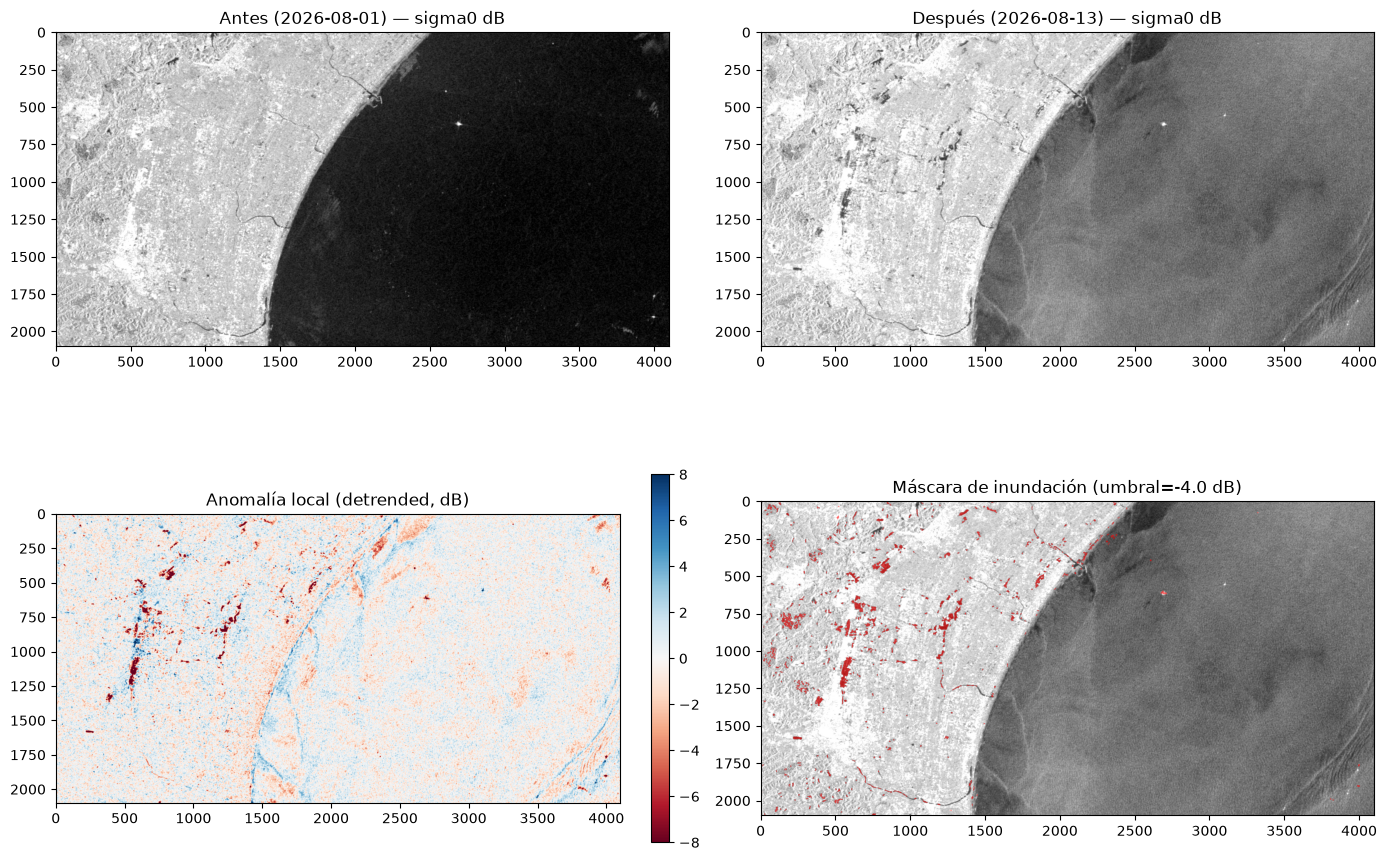

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
vmin, vmax = np.nanpercentile(before_db, [2, 98])

axes[0, 0].imshow(before_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0, 0].set_title(f"Antes ({oami_dates[0]}) — sigma0 dB")

axes[0, 1].imshow(after_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0, 1].set_title(f"Después ({oami_dates[1]}) — sigma0 dB")

im = axes[1, 0].imshow(anomaly_db, cmap="RdBu", vmin=-8, vmax=8)
axes[1, 0].set_title("Anomalía local (detrended, dB)")
plt.colorbar(im, ax=axes[1, 0], fraction=0.03)

axes[1, 1].imshow(after_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[1, 1].imshow(np.ma.masked_where(~flood_mask, flood_mask), cmap="autumn", alpha=0.6)
axes[1, 1].set_title(f"Máscara de inundación (umbral={FLOOD_ANOMALY_THRESHOLD_DB} dB)")

plt.tight_layout()
plt.show()

In [ ]:
OUT_DIR = Path(r"C:\Users\Pedro\Documents\PSS\data\chiba info all")
OUT_DIR.mkdir(parents=True, exist_ok=True)

mask_path = OUT_DIR / "oamishirasato_flood_mask.tif"
anomaly_path = OUT_DIR / "oamishirasato_flood_anomaly_db.tif"

profile_common = dict(
    driver="GTiff", height=oami_height, width=oami_width, count=1,
    crs="EPSG:6668", transform=oami_transform, compress="deflate",
)

# Background (non-flood) pixels are written as 0 and flagged as nodata, so only
# the flood pixels (value 1) are treated as real data by anything that reads this.
with rasterio.open(mask_path, "w", dtype="uint8", nodata=0, **profile_common) as dst:
    dst.write(flood_mask.astype("uint8"), 1)

with rasterio.open(anomaly_path, "w", dtype="float32", nodata=np.nan, **profile_common) as dst:
    dst.write(np.where(valid, anomaly_db, np.nan).astype("float32"), 1)

print(f"Máscara guardada en: {mask_path}")
print(f"Anomalía (dB) guardada en: {anomaly_path}")

Máscara guardada en: C:\Users\Pedro\Documents\PSS\data\oamishirasato_flood_mask.tif
Anomalía (dB) guardada en: C:\Users\Pedro\Documents\PSS\data\oamishirasato_flood_anomaly_db.tif


### Comparación: máscara sin el paso de detrend

Mismo `diff_db` y mismo umbral, pero sin restar la tendencia de fondo suave. No reemplaza la máscara guardada arriba — es solo para comparar visualmente qué tanto cambia el resultado sin ese paso.

In [10]:
flood_mask_no_detrend = valid & was_land & (diff_db < FLOOD_ANOMALY_THRESHOLD_DB)
flood_mask_no_detrend = binary_opening(flood_mask_no_detrend, structure=np.ones((3, 3)))
flood_mask_no_detrend = binary_closing(flood_mask_no_detrend, structure=np.ones((3, 3)))

labels_nd, _ = label(flood_mask_no_detrend)
blob_sizes_nd = np.bincount(labels_nd.ravel())
keep_nd = np.isin(labels_nd, np.where(blob_sizes_nd >= MIN_BLOB_PIXELS)[0])
flood_mask_no_detrend = flood_mask_no_detrend & keep_nd

print(f"Sin detrend — área marcada: {flood_mask_no_detrend.sum() * pixel_area_km2:.2f} km^2 ({flood_mask_no_detrend.mean()*100:.2f}% del recorte)")
print(f"Con detrend (referencia)  — área marcada: {flood_mask.sum() * pixel_area_km2:.2f} km^2 ({flood_mask.mean()*100:.2f}% del recorte)")

Sin detrend — área marcada: 4.74 km^2 (0.45% del recorte)
Con detrend (referencia)  — área marcada: 13.62 km^2 (1.28% del recorte)


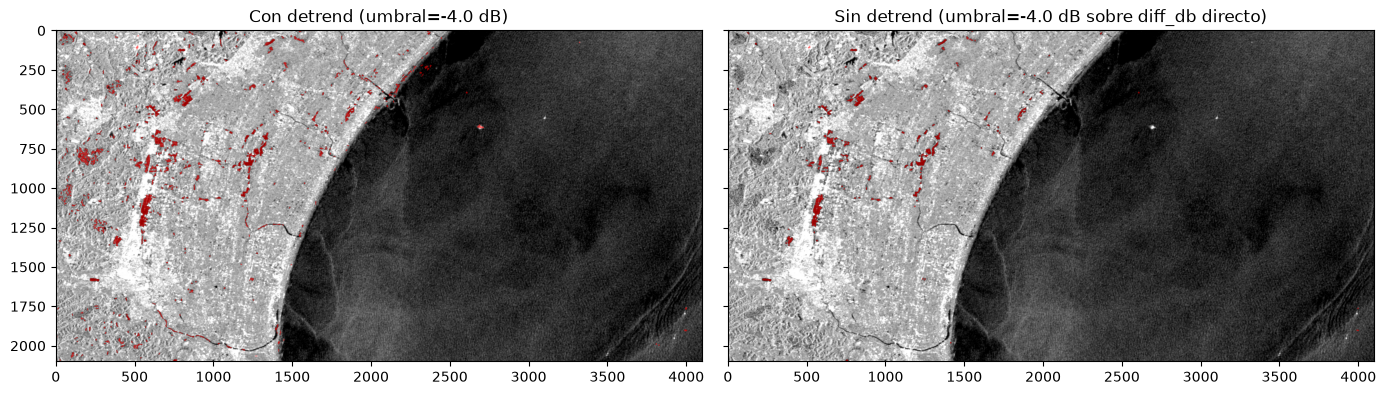

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
vmin, vmax = np.nanpercentile(after_db, [2, 98])

axes[0].imshow(after_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].imshow(np.ma.masked_where(~flood_mask, flood_mask), cmap="autumn", alpha=0.6)
axes[0].set_title(f"Con detrend (umbral={FLOOD_ANOMALY_THRESHOLD_DB} dB)")

axes[1].imshow(after_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].imshow(np.ma.masked_where(~flood_mask_no_detrend, flood_mask_no_detrend), cmap="autumn", alpha=0.6)
axes[1].set_title(f"Sin detrend (umbral={FLOOD_ANOMALY_THRESHOLD_DB} dB sobre diff_db directo)")

plt.tight_layout()
plt.show()

In [12]:
import os

mask_no_detrend_path = OUT_DIR / "oamishirasato_flood_mask_no_detrend.tif"

if mask_no_detrend_path.exists():
    try:
        os.remove(mask_no_detrend_path)
    except PermissionError as e:
        raise PermissionError(
            f"No se pudo borrar {mask_no_detrend_path} — cerrá el programa que lo tiene abierto "
            "(QGIS, vista previa del Explorador de Windows, otra sesión del notebook) y volvé a correr esta celda."
        ) from e

# Igual que la máscara principal: fondo = 0 = nodata, solo la inundación (1) es dato válido.
with rasterio.open(mask_no_detrend_path, "w", dtype="uint8", nodata=0, **profile_common) as dst:
    dst.write(flood_mask_no_detrend.astype("uint8"), 1)

print(f"Máscara (sin detrend) guardada en: {mask_no_detrend_path}")

Máscara (sin detrend) guardada en: C:\Users\Pedro\Documents\PSS\data\oamishirasato_flood_mask_no_detrend.tif


## Validación cruzada con una máscara externa

Mismo espíritu que el cruce VV+VH: tenemos una segunda máscara de inundación (`flood_mask_20260801_20260813.tif`, de otra fuente/pipeline, mismas fechas) que cubre toda Chiba a ~12 m/píxel, ya en EPSG:6668. La remuestreamos al grid de Oamishirasato (vecino más cercano, para no introducir bordes fraccionarios en una máscara binaria) y nos quedamos solo con lo que **ambas** coinciden en marcar como inundado — `floods_chiba_final_mask`.

Esto acota el resultado al área de Oamishirasato (donde tenemos nuestra propia máscara calculada), aunque el archivo externo cubra más.

In [13]:
EXTERNAL_MASK_PATH = Path(r"C:\Users\Pedro\Documents\PSS\data\export_flood_cogs\export_flood_cogs\flood_mask_20260801_20260813.tif")

external_flood_raw = np.zeros((oami_height, oami_width), dtype="uint8")
with rasterio.open(EXTERNAL_MASK_PATH) as src:
    reproject(
        source=rasterio.band(src, 1), destination=external_flood_raw,
        src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
        dst_transform=oami_transform, dst_crs="EPSG:6668", dst_nodata=0,
        resampling=Resampling.nearest,
    )

external_flood = external_flood_raw > 0
print(f"Máscara externa (remuestreada): {external_flood.sum() * pixel_area_km2:.2f} km^2 ({external_flood.mean()*100:.2f}% del recorte)")
print(f"Nuestra máscara (VV+VH):        {flood_mask.sum() * pixel_area_km2:.2f} km^2 ({flood_mask.mean()*100:.2f}% del recorte)")

Máscara externa (remuestreada): 32.17 km^2 (3.03% del recorte)
Nuestra máscara (VV+VH):        13.62 km^2 (1.28% del recorte)


floods_chiba_final_mask (ambas coinciden): 4.21 km^2 (0.40% del recorte)
  solo en la nuestra (VV+VH):    9.41 km^2
  solo en la externa:            27.96 km^2


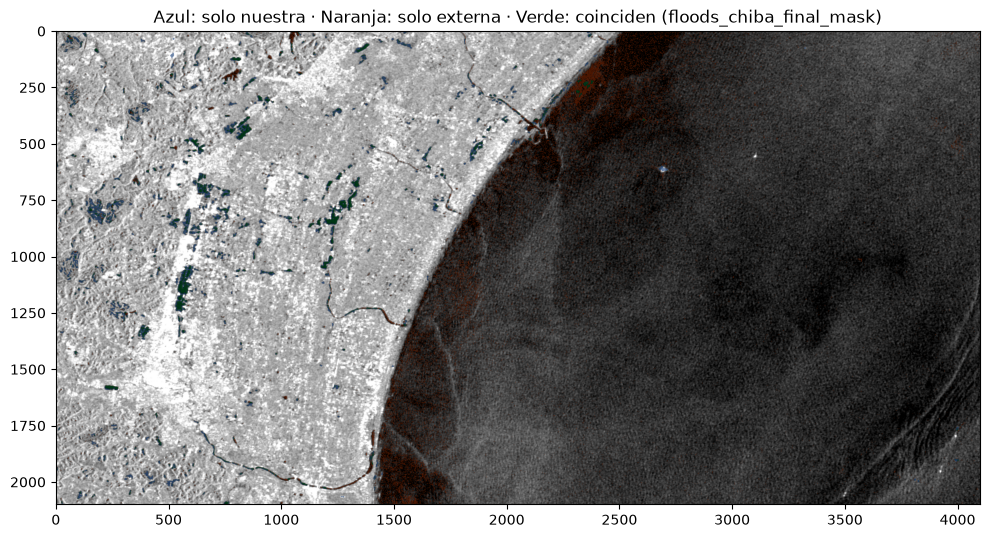

In [14]:
floods_chiba_final_mask = flood_mask & external_flood

only_ours = flood_mask & ~external_flood
only_external = external_flood & ~flood_mask

print(f"floods_chiba_final_mask (ambas coinciden): {floods_chiba_final_mask.sum() * pixel_area_km2:.2f} km^2 ({floods_chiba_final_mask.mean()*100:.2f}% del recorte)")
print(f"  solo en la nuestra (VV+VH):    {only_ours.sum() * pixel_area_km2:.2f} km^2")
print(f"  solo en la externa:            {only_external.sum() * pixel_area_km2:.2f} km^2")

fig, ax = plt.subplots(figsize=(10, 8))
vmin, vmax = np.nanpercentile(after_db, [2, 98])
ax.imshow(after_db, cmap="gray", vmin=vmin, vmax=vmax)
ax.imshow(np.ma.masked_where(~only_ours, only_ours), cmap="Blues", vmin=0, vmax=1, alpha=0.6)
ax.imshow(np.ma.masked_where(~only_external, only_external), cmap="Oranges", vmin=0, vmax=1, alpha=0.6)
ax.imshow(np.ma.masked_where(~floods_chiba_final_mask, floods_chiba_final_mask), cmap="Greens", vmin=0, vmax=1, alpha=0.8)
ax.set_title("Azul: solo nuestra · Naranja: solo externa · Verde: coinciden (floods_chiba_final_mask)")
plt.tight_layout()
plt.show()

In [15]:
final_mask_path = OUT_DIR / "floods_chiba_final_mask.tif"

if final_mask_path.exists():
    try:
        os.remove(final_mask_path)
    except PermissionError as e:
        raise PermissionError(
            f"No se pudo borrar {final_mask_path} — cerrá el programa que lo tiene abierto "
            "(QGIS, vista previa del Explorador de Windows, otra sesión del notebook) y volvé a correr esta celda."
        ) from e

# Mismo formato que las demás máscaras: fondo = 0 = nodata, solo la inundación (1) es dato válido.
with rasterio.open(final_mask_path, "w", dtype="uint8", nodata=0, **profile_common) as dst:
    dst.write(floods_chiba_final_mask.astype("uint8"), 1)

print(f"floods_chiba_final_mask guardada en: {final_mask_path}")

floods_chiba_final_mask guardada en: C:\Users\Pedro\Documents\PSS\data\floods_chiba_final_mask.tif
